# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [2]:
%pip install -q kagglehub

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

path = kagglehub.dataset_download('hellbuoy/car-price-prediction')
df = pd.read_csv(os.path.join(path, 'CarPrice_Assignment.csv'))
print('Кількість автомобілів:', df.shape[0])
print('Кількість ознак без price і car_ID:', df.shape[1] - 2)
print('Стовпці:', df.columns.tolist())
print('Цільова змінна: price')
display(df.head())
df.info()
display(df.describe(include='all'))

Using Colab cache for faster access to the 'car-price-prediction' dataset.
Кількість автомобілів: 205
Кількість ознак без price і car_ID: 24
Стовпці: ['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']
Цільова змінна: price


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205,205,205,205,205,205,205,205.000000,...,205.000000,205,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
unique,NaN,NaN,147,2,2,2,5,3,2,NaN,...,NaN,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,peugeot 504,gas,std,four,sedan,fwd,front,NaN,...,NaN,mpfi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,6,185,168,115,96,120,202,NaN,...,NaN,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,103.000000,0.834146,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.756585,...,126.907317,NaN,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.021776,...,41.642693,NaN,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86.600000,...,61.000000,NaN,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,94.500000,...,97.000000,NaN,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,97.000000,...,120.000000,NaN,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,102.400000,...,141.000000,NaN,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [21]:
print('Пропущені значення:')
display(df.isna().sum())
print('Повні дублікати:', df.duplicated().sum())
print('Дублікати без car_ID:', df.drop(columns='car_ID').duplicated().sum())
print('Кількість унікальних значень:')
display(df.nunique())

Пропущені значення:


,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


Повні дублікати: 0
Дублікати без car_ID: 0
Кількість унікальних значень:


,0
car_ID,205
symboling,6
CarName,147
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,53


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [6]:
car_ids = df['car_ID'].copy()
data = df.drop(columns='car_ID').copy()

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


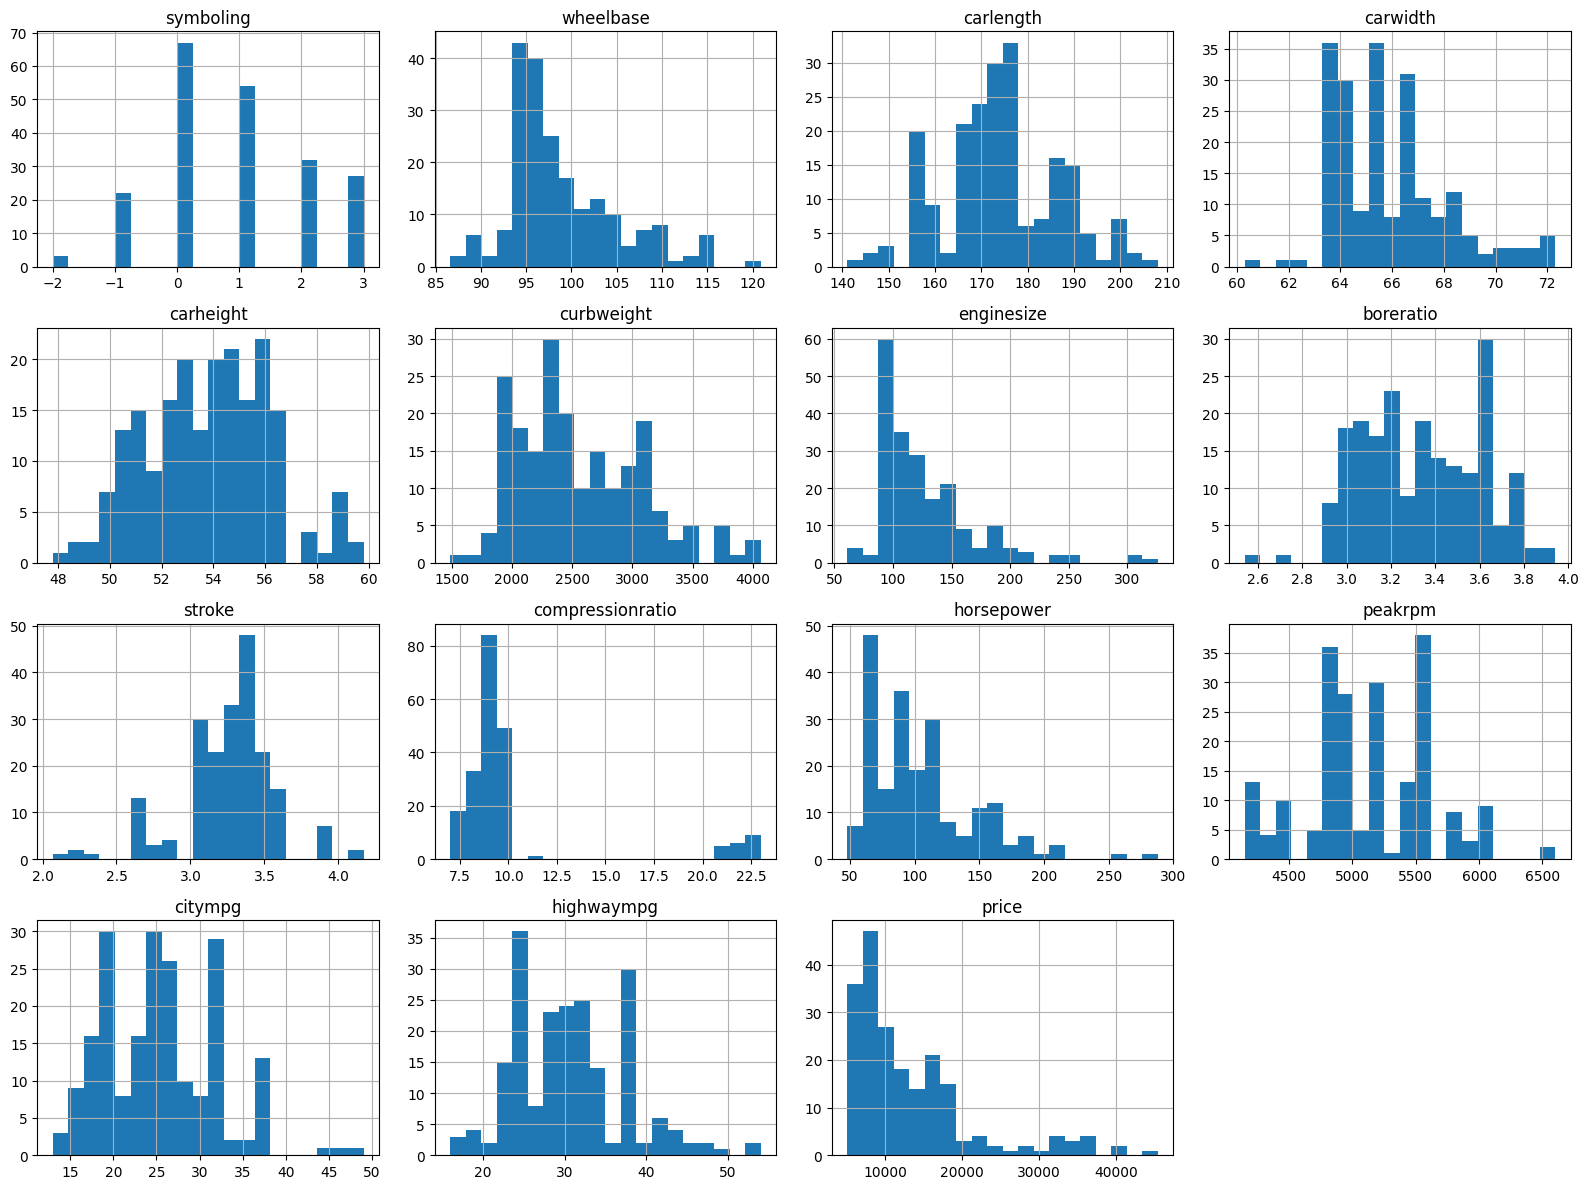

,skewness
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


In [8]:
numeric = data.select_dtypes(include='number').columns
data[numeric].hist(figsize=(16, 12), bins=20)
plt.tight_layout()
plt.show()
skewness = data[numeric].skew().sort_values(key=np.abs, ascending=False)
display(skewness.to_frame('skewness'))

Найбільша асиметрія в ознаках compressionratio, enginesize та price.
Додатна асиметрія означає довгий правий хвіст, від’ємна - лівий

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [9]:
X = data.drop(columns='price')
y = data['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = X_train.copy()
X_test = X_test.copy()
ids_train = car_ids.loc[X_train.index]
ids_test = car_ids.loc[X_test.index]
print('Train:', X_train.shape)
print('Test:', X_test.shape)

Train: (164, 24)
Test: (41, 24)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [10]:
continuous = X_train.select_dtypes(include='number').columns.drop('symboling').tolist()
q1 = X_train[continuous].quantile(0.25)
q3 = X_train[continuous].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = ((X_train[continuous] < lower) | (X_train[continuous] > upper)).sum()
display(outliers.to_frame('outliers'))
X_train[continuous] = X_train[continuous].clip(lower=lower, upper=upper, axis=1)
X_test[continuous] = X_test[continuous].clip(lower=lower, upper=upper, axis=1)

,outliers
wheelbase,6
carlength,0
carwidth,10
carheight,0
curbweight,0
enginesize,7
boreratio,1
stroke,16
compressionratio,20
horsepower,7


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


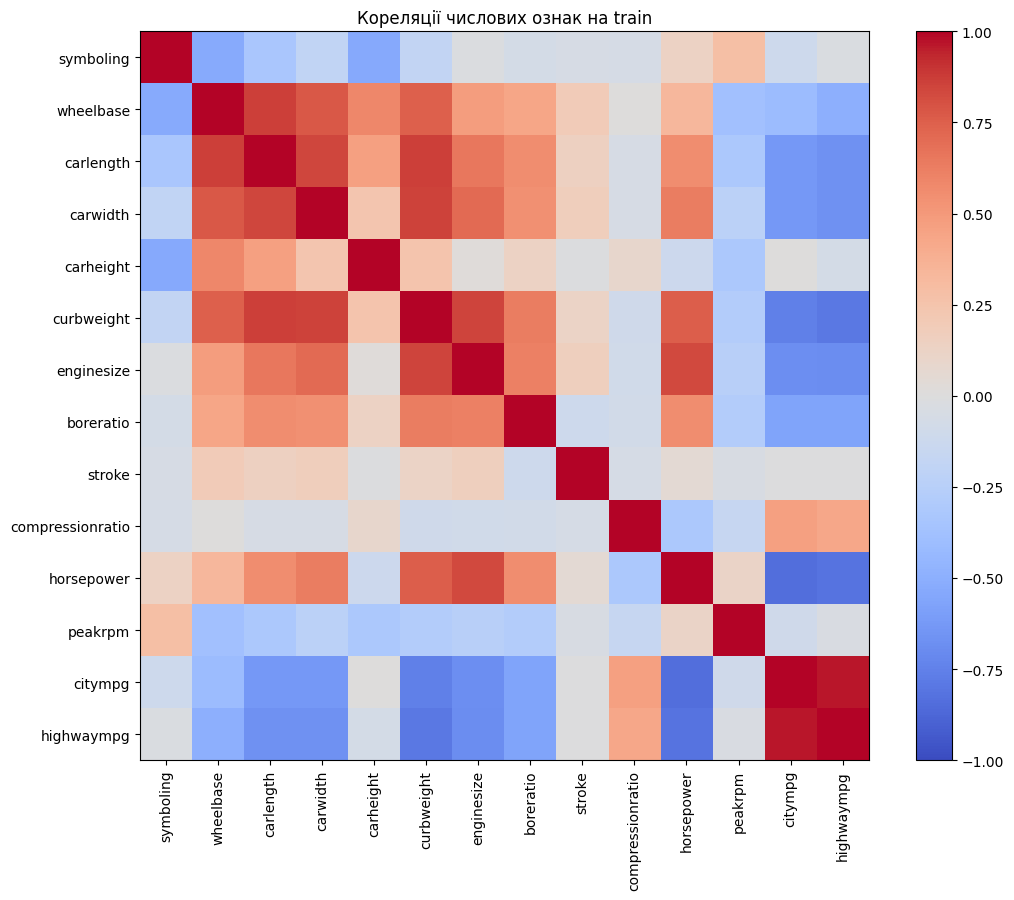

,feature1,feature2,correlation
0,wheelbase,carlength,0.867043
1,carlength,curbweight,0.865988
2,carwidth,curbweight,0.858047
3,citympg,highwaympg,0.963620


Видалено: ['carwidth', 'citympg', 'carlength']


In [11]:
corr = X_train.select_dtypes(include='number').corr()
plt.figure(figsize=(11, 9))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.colorbar()
plt.title('Кореляції числових ознак на train')
plt.tight_layout()
plt.show()
target_corr = X_train[corr.columns].corrwith(y_train).abs()
pairs = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        a = corr.columns[i]
        b = corr.columns[j]
        if abs(corr.loc[a, b]) > 0.85:
            pairs.append({'feature1': a, 'feature2': b, 'correlation': corr.loc[a, b]})
display(pd.DataFrame(pairs))
keep = []
drop_features = []
for feature in target_corr.sort_values(ascending=False).index:
    if any(abs(corr.loc[feature, other]) > 0.85 for other in keep):
        drop_features.append(feature)
    else:
        keep.append(feature)
X_train = X_train.drop(columns=drop_features)
X_test = X_test.drop(columns=drop_features)
print('Видалено:', drop_features)

Спочатку залишаємо ознаки з сильнішим зв’язком із price, потім відкидаємо сильно корельовані з ними

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [12]:
continuous = X_train.select_dtypes(include='number').columns.drop('symboling').tolist()
categorical = X_train.select_dtypes(exclude='number').columns.tolist()
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('power', PowerTransformer(method='yeo-johnson', standardize=False)),
    ('scale', StandardScaler())
])
symboling_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])
categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, continuous),
    ('symboling', symboling_pipe, ['symboling']),
    ('cat', categorical_pipe, categorical)
])
print('Неперервні:', continuous)
print('Дискретна: symboling')
print('Категоріальні:', categorical)

Неперервні: ['wheelbase', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна: symboling
Категоріальні: ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [14]:
preprocessor.fit(X_train)
transformed = preprocessor.named_transformers_['num'].transform(X_train[continuous])
transformed = pd.DataFrame(transformed, columns=continuous, index=X_train.index)
skew_table = pd.DataFrame({'before': X_train[continuous].skew(), 'after': transformed.skew()})
display(skew_table)
improved = (skew_table['after'].abs() < skew_table['before'].abs()).sum()

,before,after
wheelbase,0.935764,0.020429
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
highwaympg,0.243761,-0.012188


Асиметрія зменшилась для всіх ознак.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [15]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=10),
    'Lasso': Lasso(alpha=10, max_iter=50000),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR(C=10000, epsilon=100)
}
pipelines = {}
for name, model in models.items():
    pipeline = Pipeline([('prep', clone(preprocessor)), ('model', model)])
    pipeline.fit(X_train, y_train)
    pipelines[name] = pipeline

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [17]:
results = []
predictions = {}
for name, pipeline in pipelines.items():
    pred = pipeline.predict(X_test)
    predictions[name] = pred
    results.append({
        'model': name,
        'R2': r2_score(y_test, pred),
        'MAE': mean_absolute_error(y_test, pred),
        'MSE': mean_squared_error(y_test, pred),
        'MAPE': mean_absolute_percentage_error(y_test, pred) * 100,
        'train R2': r2_score(y_train, pipeline.predict(X_train))
    })
results = pd.DataFrame(results).set_index('model').sort_values('R2', ascending=False)
display(results.round(3))

,R2,MAE,MSE,MAPE,train R2
model,,,,,
Random Forest,0.954,1367.501,3.648690e+06,9.949,0.986
Gradient Boosting,0.934,1660.090,5.244394e+06,12.366,0.992
SVR,0.859,2153.555,1.114923e+07,16.929,0.967
Lasso,0.775,2608.846,1.774613e+07,19.380,0.971
Ridge,0.731,3195.847,2.121602e+07,27.984,0.864
Linear Regression,0.530,4184.432,3.711970e+07,30.634,0.993


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування ціни є задачею регресії, бо ціна - неперервна числова величина. логістична регресія розв’язує задачі класифікації та прогнозує ймовірності класів, тому не підходить для безпосереднього прогнозування ціни.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


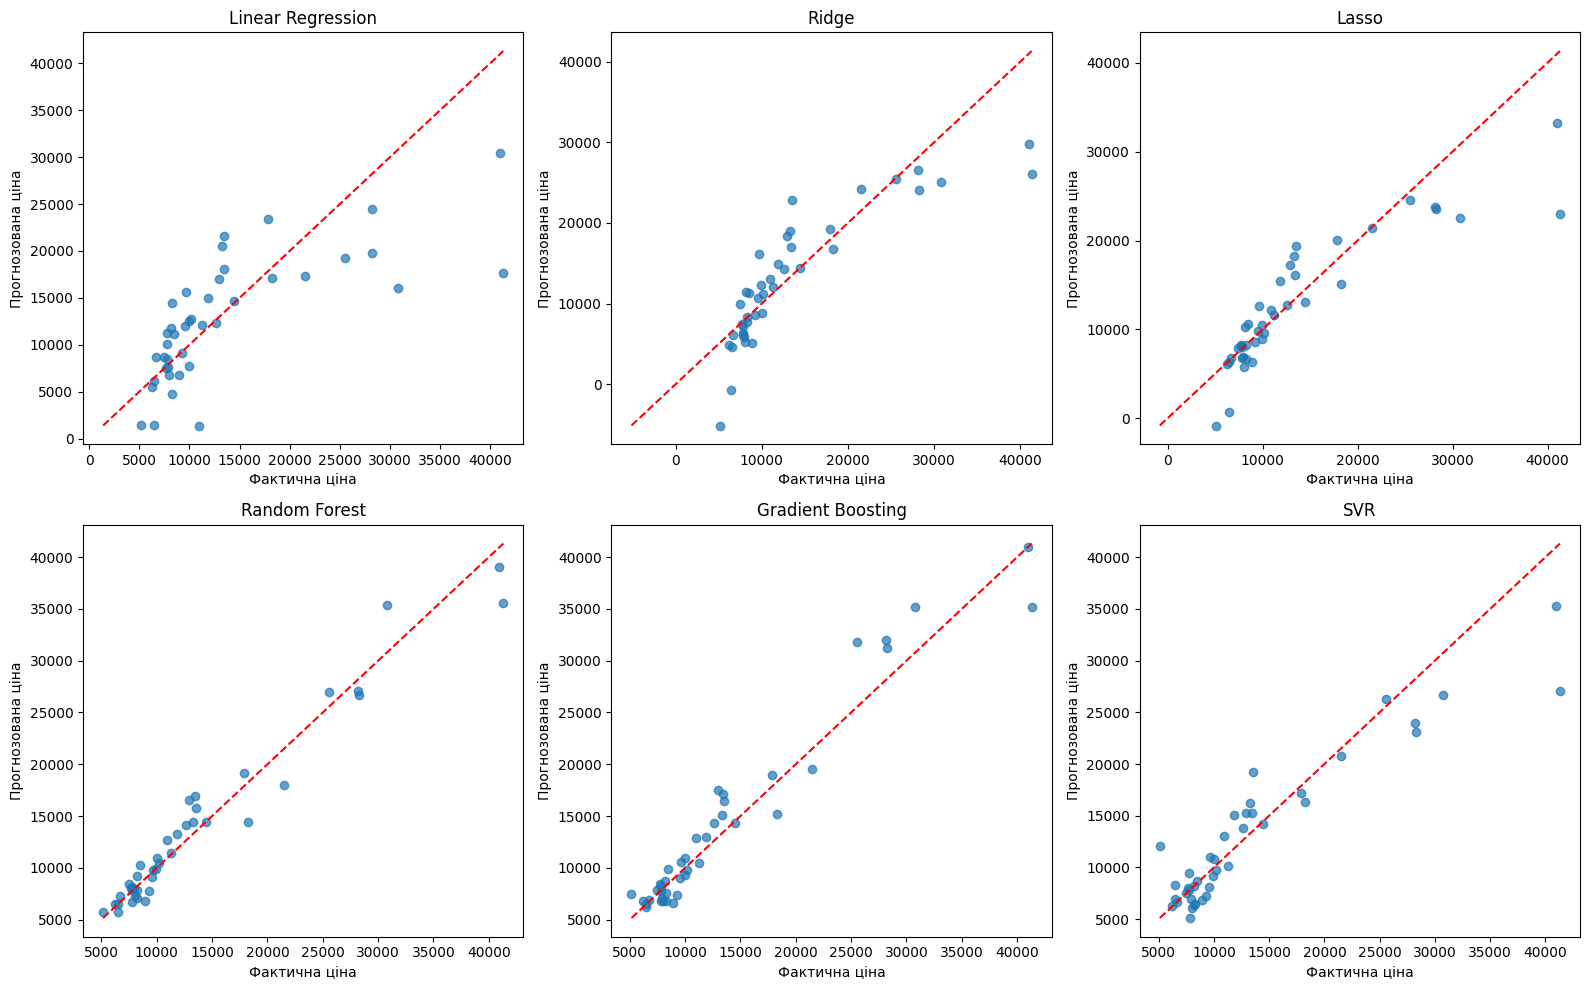

Linear Regression : найбільша помилка = 23695.35 , car_ID = 17
Ridge : найбільша помилка = 15243.56 , car_ID = 17
Lasso : найбільша помилка = 18327.07 , car_ID = 17
Random Forest : найбільша помилка = 5765.25 , car_ID = 17
Gradient Boosting : найбільша помилка = 6283.83 , car_ID = 68
SVR : найбільша помилка = 14270.94 , car_ID = 17


In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(y_test, pred, alpha=0.7)
    low = min(y_test.min(), pred.min())
    high = max(y_test.max(), pred.max())
    ax.plot([low, high], [low, high], 'r--')
    ax.set_title(name)
    ax.set_xlabel('Фактична ціна')
    ax.set_ylabel('Прогнозована ціна')
plt.tight_layout()
plt.show()
for name, pred in predictions.items():
    error = np.abs(y_test.to_numpy() - pred)
    i = error.argmax()
    print(name, ': найбільша помилка =', round(error[i], 2), ', car_ID =', ids_test.iloc[i])

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [20]:
sample = X_test.sample(n=10, random_state=42)
sample_pred = pipelines['Random Forest'].predict(sample)
sample_results = pd.DataFrame({
    'car_ID': ids_test.loc[sample.index],
    'actual_price': y_test.loc[sample.index],
    'predicted_price': sample_pred
})
sample_results['absolute_error'] = abs(sample_results['actual_price'] - sample_results['predicted_price'])
sample_results['percentage_error'] = sample_results['absolute_error'] / sample_results['actual_price'] * 100
display(sample_results.round(2))
print('Середня абсолютна помилка для 10 авто:', round(sample_results['absolute_error'].mean(), 2))
print('Середня відсоткова помилка:', round(sample_results['percentage_error'].mean(), 2), '%')
print('Найбільша абсолютна помилка у car_ID:', sample_results.loc[sample_results['absolute_error'].idxmax(), 'car_ID'])

,car_ID,actual_price,predicted_price,absolute_error,percentage_error
25,26,6692.0,7242.46,550.45,8.23
175,176,9988.0,10928.84,940.84,9.42
147,148,10198.0,10466.21,268.21,2.63
16,17,41315.0,35549.75,5765.25,13.95
68,69,28248.0,26720.33,1527.67,5.41
146,147,7463.0,8405.92,942.92,12.63
143,144,9960.0,9898.08,61.92,0.62
84,85,14489.0,14408.73,80.27,0.55
194,195,12940.0,16551.88,3611.88,27.91
159,160,7788.0,7826.62,38.61,0.50


Середня абсолютна помилка для 10 авто: 1378.8
Середня відсоткова помилка: 8.19 %
Найбільша абсолютна помилка у car_ID: 17


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Найкращий результат на цьому train/test розбитті показав Random Forest: R^2 = 0,954, MAE = 1367,50, MSE ≈ 3 648 690 та MAPE = 9,95%. Він має найкращі значення всіх чотирьох тестових метрик серед розглянутих моделей. Gradient Boosting посів друге місце з R^2 = 0,933 та MAPE = 12,49%, далі розташувалися SVR (R^2 = 0,859), Lasso (0,775), Ridge (0,731) та Linear Regression (0,530).
У Random Forest середня абсолютна помилка становить близько 1368 одиниць ціни, але для окремих автомобілів відхилення значно більше. Для випадкових 10 автомобілів MAE становить 1378,80, а MAPE - 8,19%; найбільша абсолютна помилка у цій підвибірці отримана для car_ID = 17 і дорівнює приблизно 5765. На графіках точні прогнози лежать поблизу діагоналі, а великі відхилення показують, що високе загальне R^2 не гарантує точності для кожного авто.
У Linear Regression навчальне R^2 = 0,993, а тестове - лише 0,530, що вказує на суттєве перенавчання; велика кількість категорій CarName на невеликому наборі даних може цьому сприяти. Помітний розрив є також у Lasso та SVR, тоді як у Random Forest він менший: 0,986 на train проти 0,954 на test. Порівняно зі звичайною лінійною регресією Ridge та Lasso дали кращі тестові результати.
Передобробка зберегла всі спостереження, обмежила крайні значення числових ознак, прибрала надлишкові сильно корельовані ознаки та зменшила абсолютну асиметрію всіх 10 неперервних ознак, що залишилися.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
